[13929872.64455245]
[10306582.37422079]
[7625999.18237673]
[5642849.69326854]
[4175675.71851866]
[3090230.83195734]
[2287196.82094014]
[1693096.06938209]
[1253568.35550934]
[928396.89128833]
[687828.48611463]
[509851.12972016]
[378179.89312088]
[280766.8575313]
[208698.72973386]
[155381.27570385]
[115935.94816237]
[86753.4994753]
[65163.7354763]
[49191.19268689]
[37374.38339803]
[28632.06953731]
[22164.32937972]
[17379.36470576]
[13839.35126131]
[11220.37783611]
[9282.80838638]
[7849.35533562]
[6788.85776037]
[6004.28016513]
[5423.83373397]
[4994.40765352]
[4676.70947326]
[4441.66984614]
[4267.78268312]
[4139.13734594]
[4043.96282366]
[3973.55068504]
[3921.4582571]
[3882.91912046]
[3854.40698198]
[3833.3130189]
[3817.70717153]
[3806.16154282]
[3797.61974572]
[3791.30024382]
[3786.62484071]
[3783.16577503]
[3780.60658031]
[3778.71312826]
[3777.31220606]
[3776.27566738]
[3775.50870698]
[3774.94118601]
[3774.52121437]
[3774.21040269]
[3773.98034975]
[3773.81004376]
[3773.68393976]
[3773.5

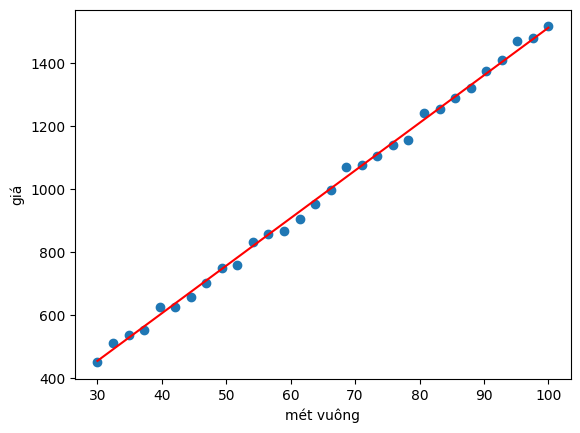

Giá nhà cho 50m^2 là :  [755.68795083]


In [ ]:
#Lab 1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#numOfPoint = 30
#noise = np.random.normal(0,1,numOfPoint).reshape(-1,1)
#x = np.linspace(30, 100, numOfPoint).reshape(-1,1)
#N = x.shape[0]
#y = 15*x + 8 + 20*noise
#plt.scatter(x, y)

data = pd.read_csv('data_linear.csv').values
N = data.shape[0]
x = data[:, 0].reshape(-1, 1)
y = data[:, 1].reshape(-1, 1)
plt.scatter(x, y)
plt.xlabel('mét vuông')
plt.ylabel('giá')

x = np.hstack((np.ones((N, 1)), x))

w = np.array([0.,1.]).reshape(-1,1)

numOfIteration = 100
cost = np.zeros((numOfIteration,1))
learning_rate = 0.000001
for i in range(1, numOfIteration):
    r = np.dot(x, w) - y
    cost[i] = 0.5*np.sum(r*r)
    w[0] -= learning_rate*np.sum(r)
    # correct the shape dimension
    w[1] -= learning_rate*np.sum(np.multiply(r, x[:,1].reshape(-1,1)))
    print(cost[i])
predict = np.dot(x, w)
plt.plot((x[0][1], x[N-1][1]),(predict[0], predict[N-1]), 'r')
plt.show()

x1 = 50
y1 = w[0] + w[1] * 50
print('Giá nhà cho 50m^2 là : ', y1)

### Giải thích Code và Nhận xét Kết quả

#### 1. Giải thích các bước thực hiện trong code:
* **Đọc dữ liệu:** Chương trình sử dụng thư viện `pandas` để đọc tập dữ liệu từ file `data_linear.csv`, sau đó tách thành biến độc lập `x` (diện tích - mét vuông) và biến phụ thuộc `y` (giá nhà).
* **Khởi tạo ma trận thiết kế:** Cột chứa toàn giá trị `1` được thêm vào bên trái của `x` để đại diện cho hệ số tự do (bias/intercept) $w_0$, tạo thành ma trận thiết kế nhằm tính toán dưới dạng ma trận: $\hat{y} = x \cdot w$.
* **Thuật toán Gradient Descent:**
  * Khởi tạo trọng số ban đầu $w = [0, 1]^T$.
  * Sử dụng vòng lặp với $100$ phân kỳ (iterations) và hệ số học tập (learning rate) $\alpha = 0.000001$.
  * Trong mỗi vòng lặp, thuật toán tính toán sai số dự báo $r = \hat{y} - y$, tính giá trị hàm mất mát (loss/cost), rồi cập nhật lại bộ trọng số $w_0$ và $w_1$ theo hướng giảm dần của đạo hàm.
* **Dự báo:** Sau khi tìm được bộ trọng số tối ưu, mô hình vẽ đường tiệm cận biểu diễn mối tương quan tuyến tính và tiến hành dự báo giá nhà cho căn hộ có diện tích $50m^2$.

#### 2. Nhận xét kết quả:
* **Sự hội tụ của hàm mất mát (Cost/Loss):**
  * Giá trị Loss ở những vòng lặp đầu tiên rất lớn (khoảng $13,929,872$), nhưng giảm cực kỳ nhanh chóng sau mỗi bước nhảy.
  * Đến khoảng vòng lặp thứ $35$, giá trị Loss bắt đầu tiệm cận đi ngang và ổn định ở mức quanh $3,773$. Điều này chứng tỏ tốc độ hội tụ nhanh và hệ số học tập $\alpha = 10^{-6}$ được lựa chọn khá phù hợp đối với tập dữ liệu này.
* **Kết quả dự báo:**
  * Giá nhà dự báo cho căn hộ diện tích $50m^2$ đạt kết quả khoảng **$755.69$** (đơn vị tùy thuộc vào tập dữ liệu gốc, ví dụ: triệu VNĐ hoặc tỷ VNĐ).
  * Đường thẳng hồi quy màu đỏ trên biểu đồ khớp khá tốt với xu hướng phân bổ của các điểm dữ liệu thực tế, cho thấy mô hình hồi quy tuyến tính đơn biến hoạt động hiệu quả trên tập dữ liệu này.